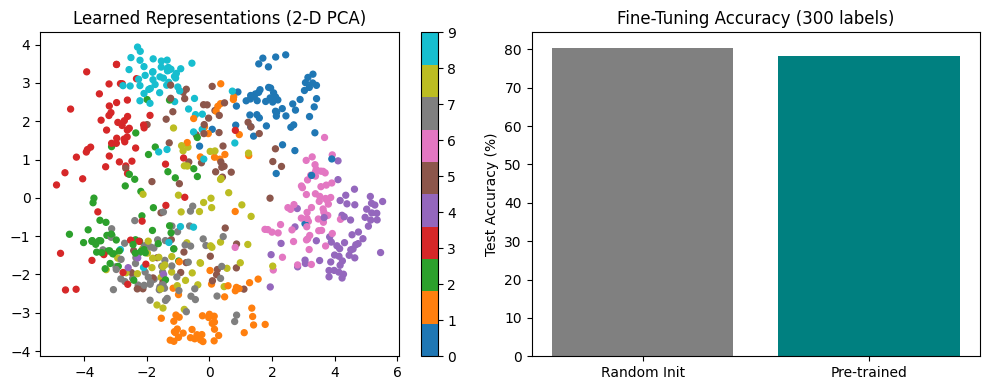

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from tensorflow.keras import layers, models

digits = load_digits()
X = digits.data / 16.0
y = digits.target
X_tr, y_tr, X_te, y_te = X[:1200], y[:1200], X[1200:], y[1200:]

# Lightweight pre-training via autoencoder hidden layer
ae = models.Sequential([
    layers.Input(shape=(64,)),
    layers.Dense(32, activation="relu", name="pre_h1"),
    layers.Dense(64, activation="sigmoid")
])
ae.compile(optimizer="adam", loss="mse")
ae.fit(X_tr, X_tr, epochs=25, batch_size=64, verbose=0)

# Functional DBN so layer outputs and feature extractor work cleanly
inp = layers.Input(shape=(64,))
pre_layer = layers.Dense(32, activation="relu")
h_out = pre_layer(inp)
out = layers.Dense(10, activation="softmax")(h_out)
dbn = models.Model(inp, out)
pre_layer.set_weights(ae.get_layer("pre_h1").get_weights())
dbn.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
dbn.fit(X_tr[:300], y_tr[:300], epochs=20, batch_size=32, verbose=0)
_, dbn_acc = dbn.evaluate(X_te, y_te, verbose=0)

rnd = models.Sequential([
    layers.Input(shape=(64,)),
    layers.Dense(32, activation="relu"),
    layers.Dense(10, activation="softmax")
])
rnd.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
rnd.fit(X_tr[:300], y_tr[:300], epochs=20, batch_size=32, verbose=0)
_, rnd_acc = rnd.evaluate(X_te, y_te, verbose=0)

feat_fn = models.Model(inp, h_out)
z2d = PCA(n_components=2).fit_transform(feat_fn.predict(X_te, verbose=0))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sc = axes[0].scatter(z2d[:, 0], z2d[:, 1], c=y_te, cmap="tab10", s=18)
axes[0].set_title("Learned Representations (2-D PCA)")
plt.colorbar(sc, ax=axes[0])
axes[1].bar(["Random Init", "Pre-trained"], [rnd_acc * 100, dbn_acc * 100], color=["gray", "teal"])
axes[1].set_ylabel("Test Accuracy (%)")
axes[1].set_title("Fine-Tuning Accuracy (300 labels)")
plt.tight_layout()
plt.show()